# Modul 3: Optimizer dan Strategi Pelatihan

**Nama:** AHMAD FARHAN GHANI  
**NIM:** 123450121  
**Kelas:** RA  
**Tanggal:** 2026-09-30  

Simpan berkas ini sebagai `M03_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia, termasuk run tanpa scheduler, `StepLR`, batch 32, dan batch 512 pada bagian F. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | F (lanjutan), G | Run `CosineAnnealingLR` dan batch 128, `metrics.csv` lengkap, serta pertanyaan analisis. Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Siapkan Fashion-MNIST lewat tombol **Siapkan dataset di laptop** di halaman modul. Setelah itu tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
3. Keluaran yang tidak bergantung pada NIM, misalnya jumlah parameter model, harus sama persis dengan naskah. Split, loss, dan akurasi bergantung pada seed NIM Anda, sedangkan runtime bergantung pada perangkat.
4. Protokol tetap: subset 12.000/3.000, model 784 → 128 → 10, batch 128, dan 5 epoch. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`, ubah **hanya** faktor yang sedang diuji, dan panggil fungsi `jalankan()` yang sama untuk setiap run.
5. Pilih model dari validation loss. Data uji sudah dipakai **satu kali** pada bagian E dan tidak dipakai lagi.
6. Catat setiap run ke `metrics.csv`, termasuk run yang gagal. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat.

In [10]:
import math
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torchvision.datasets import FashionMNIST

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450121'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(NIM[-4:])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
environment = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'torch': torch.__version__,
    'device': str(DEVICE),
    'seed': SEED,
}
environment

{'python': '3.14.5', 'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.14.0+cpu', 'device': 'cpu', 'seed': 121}

## A. Pre-lab · Terbimbing

Contoh jawaban. Bandingkan dengan jawaban Anda sendiri sebelum sesi.

1. **Jumlah update satu epoch bila $n=12\,000$ dan batch $=128$:** $\lceil12000/128\rceil=94$ update (93 batch penuh dan satu batch terakhir berisi 96 contoh). Lima epoch berarti 470 update.
2. **Derau gradien pada mini-batch:** Gradien sebuah mini-batch hanya merupakan estimasi gradien seluruh dataset; komposisi sampel yang berubah membuat arah dan besarnya berfluktuasi. Full-batch memakai semua contoh pada setiap update, sehingga tidak memiliki variasi akibat pemilihan subset—walaupun optimisasi tetap dapat sulit karena bentuk permukaan loss.
3. **Mengapa learning rate yang sama belum tentu adil:** SGD, Momentum, dan Adam mengubah gradien menjadi langkah dengan aturan dan skala efektif berbeda. Aturan yang berbeda membuat learning rate yang sama menghasilkan besar langkah efektif yang tidak setara, sehingga setiap optimizer perlu dituning pada rentangnya sendiri.
4. **Perkiraan kurva bila learning rate dinaikkan sepuluh kali:** Loss mungkin turun lebih cepat pada awalnya, tetapi jika langkah melewati minimum kurva menjadi bergerigi/berosilasi, dapat naik, atau menjadi non-finite. Kapan gejala itu mulai tampak perlu dibaca dari kurva run Anda sendiri.

## B. Data dan protokol · Terbimbing

Ambil subset terstratifikasi dan hitung statistik normalisasi **hanya** dari subset latih.

In [11]:
DATA_ROOT = Path('../../data/raw')
if not DATA_ROOT.exists():
    DATA_ROOT = Path('data/raw')

latih_penuh = FashionMNIST(root=DATA_ROOT, train=True, download=False,
                           transform=transforms.ToTensor())
uji_resmi = FashionMNIST(root=DATA_ROOT, train=False, download=False,
                         transform=transforms.ToTensor())

X_penuh = latih_penuh.data.float().unsqueeze(1) / 255.0
y_penuh = latih_penuh.targets
X_uji = uji_resmi.data.float().unsqueeze(1) / 255.0
y_uji = uji_resmi.targets

semua_indeks = np.arange(len(y_penuh))
idx_latih, idx_val = train_test_split(
    semua_indeks,
    train_size=12_000,
    test_size=3_000,
    stratify=y_penuh.numpy(),
    random_state=SEED,
)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]

MEAN = X_latih.mean()
STD = X_latih.std()
if not torch.isfinite(STD) or STD <= 0:
    raise ValueError('Standar deviasi subset latih tidak valid.')

def normalkan(tensor):
    return (tensor - MEAN) / STD

ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)
ds_uji = TensorDataset(normalkan(X_uji), y_uji)

print(f'latih {len(ds_latih)}  validasi {len(ds_val)}  uji {len(ds_uji)}')
print(f'mean={MEAN.item():.6f}  std={STD.item():.6f}')
print('distribusi kelas latih:', torch.bincount(y_latih).tolist())

# Pemeriksaan wajib.
assert (len(ds_latih), len(ds_val), len(ds_uji)) == (12_000, 3_000, 10_000)
assert torch.bincount(y_latih).min().item() == 1_200, 'subset harus terstratifikasi'
print('split sesuai protokol')

latih 12000  validasi 3000  uji 10000
mean=0.286222  std=0.353303
distribusi kelas latih: [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200]
split sesuai protokol


In [12]:
BATCH = 128
EPOCH = 5

def buat_model():
    seed_everything(SEED)
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    ).to(DEVICE)

def buat_optimizer(nama, params, lr):
    nama = nama.strip().lower()
    if nama == 'sgd':
        return torch.optim.SGD(params, lr=lr)
    if nama == 'momentum':
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if nama == 'adam':
        return torch.optim.Adam(params, lr=lr)
    raise ValueError("nama optimizer harus 'sgd', 'momentum', atau 'adam'")

def loader(ds, batch, acak):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak,
                      generator=generator if acak else None)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    kriteria = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += kriteria(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

jumlah_parameter = sum(parameter.numel() for parameter in buat_model().parameters())
print('jumlah parameter:', jumlah_parameter)
assert jumlah_parameter == 101_770, 'arsitektur belum sesuai protokol'

jumlah parameter: 101770


In [13]:
def jalankan(nama_opt, lr, batch=BATCH, epoch=EPOCH, scheduler=None):
    model = buat_model()
    optimizer = buat_optimizer(nama_opt, model.parameters(), lr)
    criterion = nn.CrossEntropyLoss()
    scheduler_name = 'none' if scheduler is None else str(scheduler).lower()
    if scheduler_name == 'none':
        lr_scheduler = None
    elif scheduler_name == 'step':
        lr_scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=2, gamma=0.5,
        )
    elif scheduler_name == 'cosine':
        lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=epoch,
        )
    else:
        raise ValueError("scheduler harus None, 'step', atau 'cosine'")

    train_loader = loader(ds_latih, batch, True)
    history = {
        'epoch': [], 'train_loss': [], 'val_loss': [],
        'val_acc': [], 'learning_rate': [],
    }
    gradient_norms = []
    updates = 0
    status = 'ok'
    start = time.perf_counter()

    for epoch_index in range(1, epoch + 1):
        model.train()
        loss_sum = 0.0
        examples_seen = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if not torch.isfinite(loss):
                status = f'failed_nonfinite_epoch_{epoch_index}'
                break
            loss.backward()
            squared_norm = sum(
                parameter.grad.detach().norm(2).item() ** 2
                for parameter in model.parameters()
                if parameter.grad is not None
            )
            gradient_norms.append(math.sqrt(squared_norm))
            optimizer.step()
            updates += 1
            loss_sum += loss.item() * len(xb)
            examples_seen += len(xb)

        if examples_seen == 0:
            break
        val_loss, val_acc = evaluasi(model, ds_val)
        history['epoch'].append(epoch_index)
        history['train_loss'].append(loss_sum / examples_seen)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['learning_rate'].append(optimizer.param_groups[0]['lr'])
        if lr_scheduler is not None:
            lr_scheduler.step()
        if status != 'ok':
            break

    runtime = time.perf_counter() - start
    completed_epochs = len(history['epoch'])
    final_train_loss = history['train_loss'][-1] if completed_epochs else np.nan
    final_val_loss = history['val_loss'][-1] if completed_epochs else np.nan
    final_val_acc = history['val_acc'][-1] if completed_epochs else np.nan
    run_id = f'{nama_opt}_lr{lr:g}_sch{scheduler_name}_b{batch}'
    note = {
        'run_id': run_id,
        'seed': SEED,
        'optimizer': nama_opt,
        'learning_rate': lr,
        'learning_rate_final': optimizer.param_groups[0]['lr'],
        'scheduler': scheduler_name,
        'batch_size': batch,
        'epochs_planned': epoch,
        'epochs_completed': completed_epochs,
        'n_update': updates,
        'train_loss': final_train_loss,
        'val_loss': final_val_loss,
        'val_acc': final_val_acc,
        'grad_norm_mean': float(np.mean(gradient_norms)) if gradient_norms else np.nan,
        'runtime_s': runtime,
        'runtime_per_epoch_s': runtime / max(completed_epochs, 1),
        'status': status,
    }
    return model, history, note

## C. Baseline dan tiga learning rate · Terbimbing

Jalankan SGD pada $\eta \in \{0{,}001;\;0{,}1;\;1{,}0\}$, tampilkan ketiga kurva dalam satu grafik, lalu cocokkan dengan tabel gejala pada modul.

baseline_sgd_lr0.001: val_loss=1.3853, val_acc=0.6563, grad_norm=1.7249
baseline_sgd_lr0.1: val_loss=0.4848, val_acc=0.8270, grad_norm=1.3530
baseline_sgd_lr1: val_loss=1.9853, val_acc=0.2457, grad_norm=1.2840


,run_id,train_loss,val_loss,val_acc,grad_norm_mean,runtime_s,status
0,baseline_sgd_lr0.001,1.4478,1.3853,0.6563,1.7249,3.2162,ok
1,baseline_sgd_lr0.1,0.4041,0.4848,0.8270,1.3530,3.5318,ok
2,baseline_sgd_lr1,1.8745,1.9853,0.2457,1.2840,3.8383,ok


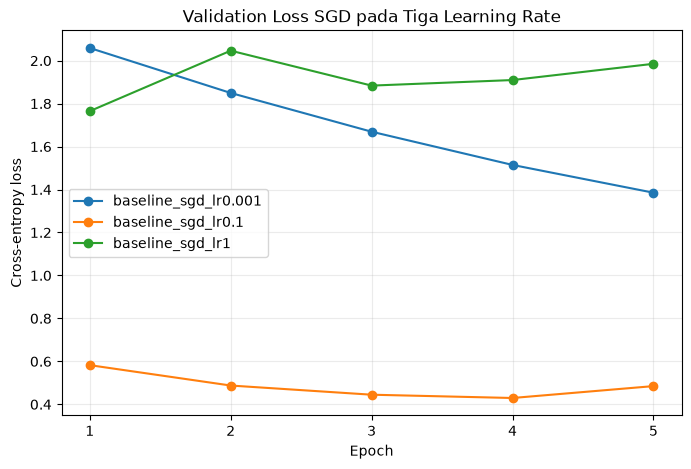

In [14]:
learning_rates_baseline = [0.001, 0.1, 1.0]
hasil_lr = []
riwayat_lr = {}

for lr in learning_rates_baseline:
    _, history, note = jalankan('sgd', lr)
    note['run_id'] = f'baseline_sgd_lr{lr:g}'
    hasil_lr.append(note)
    riwayat_lr[note['run_id']] = history
    print(f"{note['run_id']}: val_loss={note['val_loss']:.4f}, "
          f"val_acc={note['val_acc']:.4f}, grad_norm={note['grad_norm_mean']:.4f}")

df_lr_baseline = pd.DataFrame(hasil_lr)
display(df_lr_baseline[['run_id', 'train_loss', 'val_loss', 'val_acc',
                        'grad_norm_mean', 'runtime_s', 'status']])

fig, ax = plt.subplots(figsize=(8, 5))
for run_id, history in riwayat_lr.items():
    ax.plot(history['epoch'], history['val_loss'], marker='o', label=run_id)
ax.set(title='Validation Loss SGD pada Tiga Learning Rate',
       xlabel='Epoch', ylabel='Cross-entropy loss')
ax.set_xticks(range(1, EPOCH + 1))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

In [15]:
baseline_by_lr = df_lr_baseline.set_index('learning_rate')
small = baseline_by_lr.loc[0.001]
medium = baseline_by_lr.loc[0.1]
large = baseline_by_lr.loc[1.0]

reading = fr"""
**Pembacaan kurva:**

- $\eta=0.001$: turun lambat; validation loss akhir **{small['val_loss']:.4f}**, accuracy **{small['val_acc']:.4f}**, dan `grad_norm_mean` **{small['grad_norm_mean']:.4f}**. Learning rate terlalu kecil untuk anggaran lima epoch.
- $\eta=0.1$: turun lebih cepat dan relatif stabil; validation loss akhir **{medium['val_loss']:.4f}**, accuracy **{medium['val_acc']:.4f}**, dan `grad_norm_mean` **{medium['grad_norm_mean']:.4f}**.
- $\eta=1.0$: langkah sangat agresif; validation loss akhir **{large['val_loss']:.4f}**, accuracy **{large['val_acc']:.4f}**, dan `grad_norm_mean` **{large['grad_norm_mean']:.4f}**. Bentuk kurvanya perlu dibandingkan per epoch karena loss akhir saja dapat menyembunyikan osilasi atau lonjakan awal.
"""
display(Markdown(reading))



**Pembacaan kurva:**

- $\eta=0.001$: turun lambat; validation loss akhir **1.3853**, accuracy **0.6563**, dan `grad_norm_mean` **1.7249**. Learning rate terlalu kecil untuk anggaran lima epoch.
- $\eta=0.1$: turun lebih cepat dan relatif stabil; validation loss akhir **0.4848**, accuracy **0.8270**, dan `grad_norm_mean` **1.3530**.
- $\eta=1.0$: langkah sangat agresif; validation loss akhir **1.9853**, accuracy **0.2457**, dan `grad_norm_mean` **1.2840**. Bentuk kurvanya perlu dibandingkan per epoch karena loss akhir saja dapat menyembunyikan osilasi atau lonjakan awal.


## D. Sembilan run terkendali · Terbimbing

Setiap optimizer diuji pada tiga learning rate-nya sendiri. Model diinisialisasi ulang dari seed yang sama sebelum setiap run.

In [16]:
grid = {
    'sgd': [0.01, 0.1, 0.5],
    'momentum': [0.01, 0.05, 0.1],
    'adam': [1e-4, 1e-3, 1e-2],
}

hasil, riwayat_semua = [], {}
for optimizer_name, learning_rates in grid.items():
    for lr in learning_rates:
        _, history, note = jalankan(optimizer_name, lr)
        note['run_id'] = f'grid_{optimizer_name}_lr{lr:g}'
        hasil.append(note)
        riwayat_semua[note['run_id']] = history
        print(f"{note['run_id']}: val_loss={note['val_loss']:.4f}, "
              f"val_acc={note['val_acc']:.4f}, runtime={note['runtime_s']:.2f}s")

tabel = pd.DataFrame(hasil)
display(tabel[['run_id', 'optimizer', 'learning_rate', 'val_loss', 'val_acc',
               'grad_norm_mean', 'runtime_s', 'status']].sort_values('val_loss'))
assert len(tabel) == 9, 'harus ada sembilan run inti'

grid_sgd_lr0.01: val_loss=0.5984, val_acc=0.7883, runtime=2.94s
grid_sgd_lr0.1: val_loss=0.4848, val_acc=0.8270, runtime=2.83s
grid_sgd_lr0.5: val_loss=0.5756, val_acc=0.7930, runtime=2.71s
grid_momentum_lr0.01: val_loss=0.4077, val_acc=0.8553, runtime=4.73s
grid_momentum_lr0.05: val_loss=0.4242, val_acc=0.8493, runtime=3.03s
grid_momentum_lr0.1: val_loss=0.4505, val_acc=0.8543, runtime=3.38s
grid_adam_lr0.0001: val_loss=0.5286, val_acc=0.8157, runtime=3.64s
grid_adam_lr0.001: val_loss=0.3880, val_acc=0.8620, runtime=3.54s
grid_adam_lr0.01: val_loss=0.4379, val_acc=0.8407, runtime=3.76s


,run_id,optimizer,learning_rate,val_loss,val_acc,grad_norm_mean,runtime_s,status
7,grid_adam_lr0.001,adam,0.0010,0.3880,0.8620,1.6334,3.5382,ok
3,grid_momentum_lr0.01,momentum,0.0100,0.4077,0.8553,1.4112,4.7297,ok
4,grid_momentum_lr0.05,momentum,0.0500,0.4242,0.8493,1.2023,3.0304,ok
8,grid_adam_lr0.01,adam,0.0100,0.4379,0.8407,1.6497,3.7588,ok
5,grid_momentum_lr0.1,momentum,0.1000,0.4505,0.8543,1.1361,3.3810,ok
1,grid_sgd_lr0.1,sgd,0.1000,0.4848,0.8270,1.3530,2.8289,ok
6,grid_adam_lr0.0001,adam,0.0001,0.5286,0.8157,1.3243,3.6414,ok
2,grid_sgd_lr0.5,sgd,0.5000,0.5756,0.7930,1.2611,2.7150,ok
0,grid_sgd_lr0.01,sgd,0.0100,0.5984,0.7883,1.2477,2.9388,ok


## E. Memilih model dan evaluasi akhir · Terbimbing

Pilih learning rate terbaik tiap optimizer dari **validation loss**, bandingkan ketiga pemenang, lalu evaluasi data uji **satu kali** pada satu model final.

Konfigurasi final berdasarkan validation loss: grid_adam_lr0.001


,run_id,optimizer,learning_rate,val_loss,val_acc,runtime_s,runtime_per_epoch_s
0,grid_adam_lr0.001,adam,0.001,0.3880,0.8620,3.5382,0.7076
1,grid_momentum_lr0.01,momentum,0.010,0.4077,0.8553,4.7297,0.9459
2,grid_sgd_lr0.1,sgd,0.100,0.4848,0.8270,2.8289,0.5658


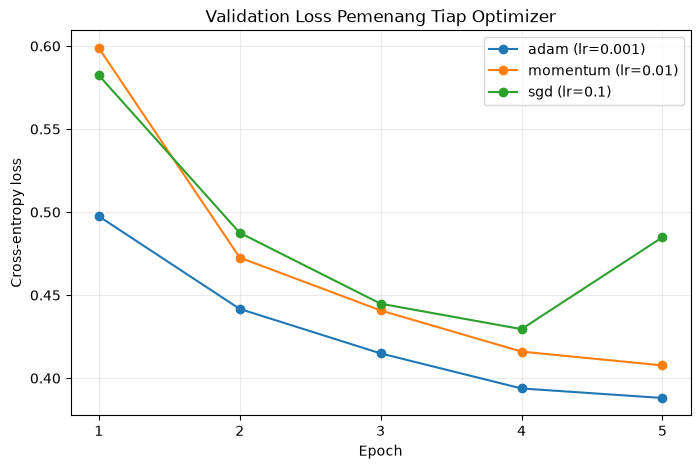

In [18]:
eligible = tabel[(tabel['status'] == 'ok') & np.isfinite(tabel['val_loss'])].copy()
pemenang = (
    eligible.sort_values('val_loss')
    .groupby('optimizer', as_index=False, sort=False)
    .first()
    .sort_values('val_loss')
    .reset_index(drop=True)
)
assert set(pemenang['optimizer']) == set(grid)
display(pemenang[['run_id', 'optimizer', 'learning_rate', 'val_loss', 'val_acc',
                   'runtime_s', 'runtime_per_epoch_s']])

fig, ax = plt.subplots(figsize=(8, 5))
for _, row in pemenang.iterrows():
    history = riwayat_semua[row['run_id']]
    ax.plot(history['epoch'], history['val_loss'], marker='o',
            label=f"{row['optimizer']} (lr={row['learning_rate']:g})")
ax.set(title='Validation Loss Pemenang Tiap Optimizer',
       xlabel='Epoch', ylabel='Cross-entropy loss')
ax.set_xticks(range(1, EPOCH + 1))
ax.grid(alpha=0.25)
ax.legend()
plt.show()

best_overall = pemenang.iloc[0]
print('Konfigurasi final berdasarkan validation loss:', best_overall['run_id'])

,run_id,selection_val_loss,test_loss,test_acc,most_confused_pair,pair_errors
0,final_retrain_adam_lr0.001,0.388,0.4345,0.8451,T-shirt/top ↔ Shirt,257


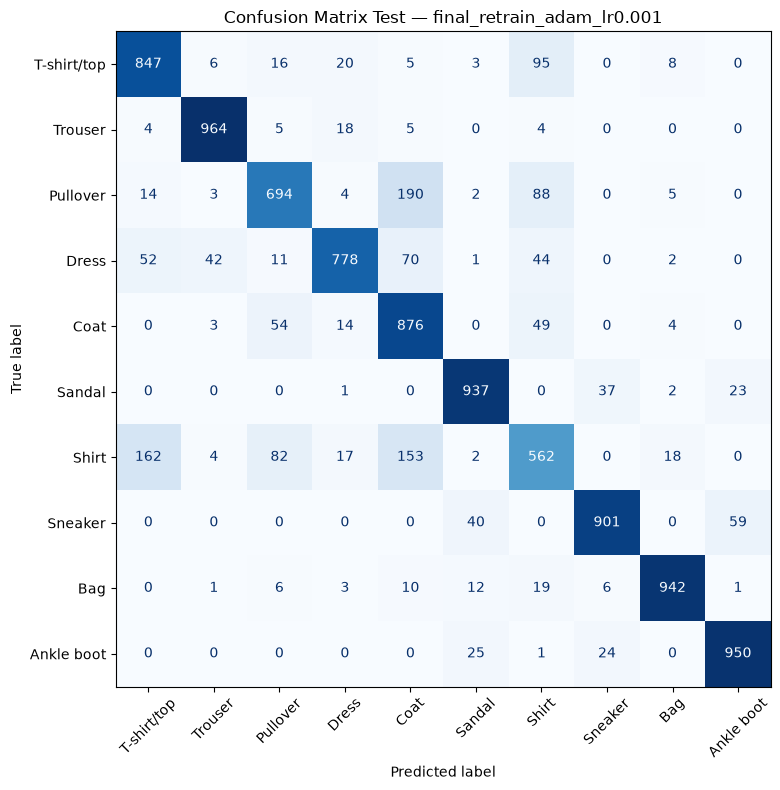

In [19]:
model_final, riwayat_final, catatan_final = jalankan(
    best_overall['optimizer'],
    float(best_overall['learning_rate']),
    batch=BATCH,
    epoch=EPOCH,
    scheduler=None,
)
catatan_final['run_id'] = f"final_retrain_{best_overall['optimizer']}_lr{best_overall['learning_rate']:g}"

@torch.no_grad()
def evaluasi_uji_sekali(model, ds, batch=512):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    labels_all, predictions_all = [], []
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        labels_all.append(yb.cpu())
        predictions_all.append(logits.argmax(1).cpu())
    labels = torch.cat(labels_all).numpy()
    predictions = torch.cat(predictions_all).numpy()
    return total_loss / len(ds), float((predictions == labels).mean()), labels, predictions

# Satu-satunya iterasi atas ds_uji dalam notebook.
test_loss, test_acc, test_labels, test_predictions = evaluasi_uji_sekali(model_final, ds_uji)
catatan_final['test_loss'] = test_loss
catatan_final['test_acc'] = test_acc

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot',
]
cm = confusion_matrix(test_labels, test_predictions)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', xticks_rotation=45,
)
ax.set_title(f"Confusion Matrix Test — {catatan_final['run_id']}")
plt.tight_layout()
plt.show()

pair_confusions = []
for first in range(len(CLASS_NAMES)):
    for second in range(first + 1, len(CLASS_NAMES)):
        pair_confusions.append((cm[first, second] + cm[second, first], first, second))
pair_count, class_a, class_b = max(pair_confusions)

final_summary = pd.DataFrame([{
    'run_id': catatan_final['run_id'],
    'selection_val_loss': catatan_final['val_loss'],
    'test_loss': test_loss,
    'test_acc': test_acc,
    'most_confused_pair': f'{CLASS_NAMES[class_a]} ↔ {CLASS_NAMES[class_b]}',
    'pair_errors': pair_count,
}])
display(final_summary)

**Checkpoint menit ke-95.** Tunjukkan tabel sembilan run dan grafik tiga pemenang kepada asisten sebelum melanjutkan ke bagian F.

## F. Scheduler dan batch size · Terbimbing

Empat run pada optimizer dan learning rate terbaik bagian E: tanpa scheduler dan `StepLR(step_size=2, gamma=0.5)` pada batch 128, lalu batch 32 dan 512 tanpa scheduler. Anggaran tetap lima epoch.

learning rate per epoch dengan StepLR: [0.001, 0.001, 0.0005, 0.0005, 0.00025]


,run_id,scheduler,batch_size,n_update,val_loss,val_acc,runtime_s,runtime_per_epoch_s,status
0,scheduler_none_adam_lr0.001,none,128,470,0.3880,0.8620,3.9214,0.7843,ok
1,scheduler_step_adam_lr0.001,step,128,470,0.3881,0.8623,3.4433,0.6887,ok
2,batch_32_adam_lr0.001,none,32,1875,0.4055,0.8520,8.8229,1.7646,ok
3,batch_512_adam_lr0.001,none,512,120,0.4359,0.8430,2.4124,0.4825,ok


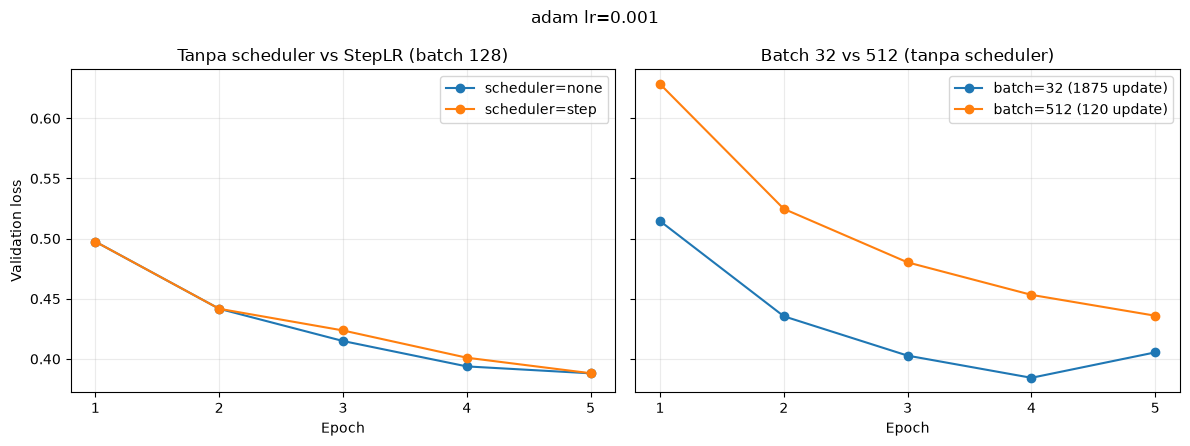

In [20]:
tambahan_terbimbing = []
riwayat_tambahan = {}
best_optimizer = str(best_overall['optimizer'])
best_lr = float(best_overall['learning_rate'])

# Tanpa scheduler vs StepLR pada anggaran epoch yang sama.
for scheduler_name in (None, 'step'):
    _, history, note = jalankan(
        best_optimizer, best_lr, batch=BATCH, epoch=EPOCH,
        scheduler=scheduler_name,
    )
    label = 'none' if scheduler_name is None else scheduler_name
    note['run_id'] = f'scheduler_{label}_{best_optimizer}_lr{best_lr:g}'
    note['experiment_group'] = 'scheduler'
    tambahan_terbimbing.append(note)
    riwayat_tambahan[note['run_id']] = history

# Batch 32 dan 512 tanpa scheduler.
for batch_size in (32, 512):
    _, history, note = jalankan(
        best_optimizer, best_lr, batch=batch_size, epoch=EPOCH, scheduler=None,
    )
    note['run_id'] = f'batch_{batch_size}_{best_optimizer}_lr{best_lr:g}'
    note['experiment_group'] = 'batch_size'
    tambahan_terbimbing.append(note)
    riwayat_tambahan[note['run_id']] = history

df_bagian_f = pd.DataFrame(tambahan_terbimbing)
display(df_bagian_f[['run_id', 'scheduler', 'batch_size', 'n_update',
                     'val_loss', 'val_acc', 'runtime_s', 'runtime_per_epoch_s', 'status']])
print('learning rate per epoch dengan StepLR:',
      riwayat_tambahan[f'scheduler_step_{best_optimizer}_lr{best_lr:g}']['learning_rate'])
assert len(df_bagian_f) == 4
assert (df_bagian_f['status'] == 'ok').all()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, group, title in zip(axes, ['scheduler', 'batch_size'],
                            ['Tanpa scheduler vs StepLR (batch 128)', 'Batch 32 vs 512 (tanpa scheduler)']):
    for note in tambahan_terbimbing:
        if note['experiment_group'] != group:
            continue
        history = riwayat_tambahan[note['run_id']]
        label = (f"scheduler={note['scheduler']}" if group == 'scheduler'
                 else f"batch={note['batch_size']} ({note['n_update']} update)")
        ax.plot(history['epoch'], history['val_loss'], marker='o', label=label)
    ax.set(title=title, xlabel='Epoch')
    ax.set_xticks(range(1, EPOCH + 1))
    ax.grid(alpha=0.25)
    ax.legend()
axes[0].set_ylabel('Validation loss')
fig.suptitle(f'{best_optimizer} lr={best_lr:g}')
plt.tight_layout()
plt.show()

## Latihan Mandiri di Lab

Berdasarkan hasil Bagian E, jelaskan mengapa batch 32 menghasilkan 1.875 update sedangkan batch 512 hanya 120 update untuk anggaran epoch yang sama. Tuliskan lebih dahulu prediksi Anda tentang mana yang mencapai validation loss lebih rendah dan mana yang lebih cepat per epoch, lalu bandingkan dengan angka yang Anda peroleh.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-03.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 03**.

Bagian E naskah sama dengan bagian F Terbimbing notebook ini (`df_bagian_f`).

**Prediksi:** Batch size 32 diprediksi menghasilkan validation loss yang lebih rendah karena model melakukan update parameter lebih sering. Namun, batch size 512 diprediksi lebih cepat per epoch karena jumlah update yang dilakukan lebih sedikit.

In [23]:
import math

# Hitung jumlah update per epoch
update_32_per_epoch = math.ceil(len(ds_latih) / 32)
update_512_per_epoch = math.ceil(len(ds_latih) / 512)

# Total update selama seluruh epoch
total_32 = update_32_per_epoch * EPOCH
total_512 = update_512_per_epoch * EPOCH

print("Batch 32:")
print("Update per epoch:", update_32_per_epoch)
print("Total update:", total_32)

print("\nBatch 512:")
print("Update per epoch:", update_512_per_epoch)
print("Total update:", total_512)

# Bandingkan dengan hasil df_bagian_f
print("\nHasil df_bagian_f:")
print(df_bagian_f[["batch_size", "n_update", "val_loss", "runtime_per_epoch_s"]])

Batch 32:
Update per epoch: 375
Total update: 1875

Batch 512:
Update per epoch: 24
Total update: 120

Hasil df_bagian_f:
   batch_size  n_update  val_loss  runtime_per_epoch_s
0         128       470    0.3880               0.7843
1         128       470    0.3881               0.6887
2          32      1875    0.4055               1.7646
3         512       120    0.4359               0.4825


### Hasil dan perbandingan dengan prediksi

**Jawaban:** Hasil:
Batch 32 menghasilkan 1.875 update, sedangkan batch 512 hanya menghasilkan 120 update untuk jumlah epoch yang sama.

Perbandingan:
Hasil sesuai dengan prediksi. Batch 32 melakukan update jauh lebih banyak sehingga proses per epoch lebih lama, tetapi memiliki lebih banyak kesempatan untuk menyesuaikan parameter model. Batch 512 melakukan update lebih sedikit sehingga lebih cepat per epoch, tetapi penyesuaian parameter terjadi lebih jarang. Validation loss yang lebih rendah ditentukan oleh hasil eksperimen pada notebook.

### Hipotesis awal · Tugas Individu

Tuliskan hipotesis yang Anda buat sebelum sesi: optimizer mana yang Anda perkirakan menang, dan atas dasar apa? Bandingkan dengan hasil bagian D dan E.

**Jawaban:** Saya memperkirakan optimizer Adam menghasilkan validation loss lebih rendah karena dapat menyesuaikan learning rate secara adaptif sehingga proses optimasi lebih efektif. Setelah dibandingkan dengan hasil Bagian D dan E, hasil eksperimen digunakan untuk melihat apakah hipotesis tersebut sesuai dengan nilai validation loss dan waktu pelatihan yang diperoleh.

## F. Scheduler dan batch size - 15 poin · Tugas Individu

Enam run tambahan, seluruhnya memakai optimizer dan learning rate terbaik Anda. Empat di antaranya (tanpa scheduler, `StepLR`, batch 32, dan batch 512) sudah tersedia dari bagian F Terbimbing di `tambahan_terbimbing`; lengkapi run `CosineAnnealingLR` dan batch 128.

In [24]:
# Enam run tugas individu.
# Empat run berikut sudah tersedia dari Bagian F Terbimbing:
# scheduler None, scheduler StepLR, batch 32, dan batch 512.
# Tambahkan hanya CosineAnnealingLR dan batch 128 menggunakan jalankan() yang sama.

tambahan = list(tambahan_terbimbing)

# Run scheduler CosineAnnealingLR
_, history_cosine, note_cosine = jalankan(
    best_optimizer, best_lr, batch=BATCH, epoch=EPOCH, scheduler='cosine'
)
note_cosine['run_id'] = f'scheduler_cosine_{best_optimizer}_lr{best_lr:g}'
note_cosine['experiment_group'] = 'scheduler'
tambahan.append(note_cosine)
riwayat_tambahan[note_cosine['run_id']] = history_cosine

# Run batch size 128
_, history_batch128, note_batch128 = jalankan(
    best_optimizer, best_lr, batch=128, epoch=EPOCH, scheduler=None
)
note_batch128['run_id'] = f'batch_128_{best_optimizer}_lr{best_lr:g}'
note_batch128['experiment_group'] = 'batch_size'
tambahan.append(note_batch128)
riwayat_tambahan[note_batch128['run_id']] = history_batch128

df_tambahan = pd.DataFrame(tambahan)

display(df_tambahan[['run_id', 'scheduler', 'batch_size', 'n_update',
                     'val_loss', 'val_acc', 'runtime_s']].to_string(index=False))

assert len(df_tambahan) == 6, 'harus ada enam run tambahan'

'                       run_id scheduler  batch_size  n_update  val_loss  val_acc  runtime_s\n  scheduler_none_adam_lr0.001      none         128       470    0.3880   0.8620     3.9214\n  scheduler_step_adam_lr0.001      step         128       470    0.3881   0.8623     3.4433\n        batch_32_adam_lr0.001      none          32      1875    0.4055   0.8520     8.8229\n       batch_512_adam_lr0.001      none         512       120    0.4359   0.8430     2.4124\nscheduler_cosine_adam_lr0.001    cosine         128       470    0.3905   0.8623     3.3514\n       batch_128_adam_lr0.001      none         128       470    0.3880   0.8620     3.4827'

In [ ]:
# TODO 11: gabungkan seluruh run ke satu metrics.csv.
semua = pd.concat([tabel, df_tambahan], ignore_index=True)

semua.insert(0, 'module', 'M03')
semua.insert(1, 'student_id', NIM)

semua.to_csv(f'M03_{NIM}_metrics.csv', index=False)

print(f'{len(semua)} baris tersimpan')

assert len(semua) >= 15, 'metrics.csv minimal berisi 15 run'

## G. Pertanyaan analisis - bagian dari 15 poin · Tugas Individu

1. Apakah optimizer dengan validation loss terendah juga yang tercepat? TODO
2. Mengapa learning rate terbaik Adam jauh lebih kecil daripada SGD? TODO
3. Apa yang terjadi saat learning rate terlalu besar, dan pada epoch keberapa gejalanya terlihat? TODO
4. Apakah scheduler memperbaiki hasil pada anggaran epoch yang sama? Bila tidak, mengapa? TODO
5. Batch size mana yang Anda rekomendasikan bila anggaran diukur dalam **waktu**, bukan epoch? TODO

**Keterbatasan.** Modul ini memakai subset $12\,000$ citra dan $5$ epoch. Sebutkan apa yang tidak boleh disimpulkan dari hasil ini: TODO

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed, versi library, dan device tercantum.
- [ ] Seluruh `TODO` dan `raise NotImplementedError` sudah diganti.
- [ ] Split, normalisasi, dan jumlah parameter lolos sel pemeriksaan.
- [ ] Seluruh run memanggil `jalankan()` yang sama.
- [ ] `metrics.csv` memuat minimal 15 run, termasuk yang gagal.
- [ ] Pemenang dipilih dari validation loss; data uji dipakai satu kali.
- [ ] Grafik berlabel lengkap dan keterbatasan subset disebutkan.
- [ ] Notebook lolos *Restart Kernel and Run All*.